# PCA on C2 CNN `dual_sal_scalars` pair embeddings

The CNN writes one `fold_{i}_pair_embeddings.npz` per outer fold, holding the pre-head
embedding for **every (query, CF) pair** in that fold's test set — `K = cf_count` rows per
sample, sample-major / CF-minor, keyed by `(sample_paths, cf_paths)`.

Because the outer folds are patient-disjoint (`StratifiedGroupKFold` on `patient_id`), the
five test sets together cover the whole cohort exactly once — so concatenating the folds is a
legitimate join, and that is what we do here.

Layout of the 4096-d vector for `dual_sal_scalars` (`mode='quad_scalars'`):

| dims | encoder | content |
|------|---------|---------|
| 0:1024 | `query_enc` | query image x_i |
| 1024:2048 | `cf_enc` | counterfactual image |
| 2048:3072 | `qcam_enc` | query Grad-CAM |
| 3072:4096 | `cfcam_enc` | CF Grad-CAM |

The scalars themselves are **not** in the embedding — `_embed_pairs` only concatenates the
image encoders and ignores the scalar tensor. They are re-attached below from the fold
prediction CSVs for colouring.

Full data is ~700k x 4096 in fp16 (~5.5 GB). Everything below is driven by `MAX_ROWS`, which
subsamples rows *per fold* so the notebook runs comfortably; set it to `None` for the full set
(and expect the fit to take minutes and a lot of RAM).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA, IncrementalPCA

RESULTS_DIR = "/work3/s251710/thesis_results"

DISEASE  = "pneumothorax"          # 'effusion' | 'pneumothorax'
CONFIG   = "dual_sal_scalars"
CF_COUNT = 16
N_FOLDS  = 5

# Rows kept per fold (random, seeded). None = keep everything.
MAX_ROWS = None
SEED     = 0

EMB_DIR = os.path.join(RESULTS_DIR, "C2_cnn", DISEASE, "late", CONFIG, f"cf_{CF_COUNT}")
CV_DIR  = os.path.join(RESULTS_DIR,
                       f"C2_custom_corrected/{DISEASE}/cv_results_cf_ensemble/cf_{CF_COUNT}/TEST_entropy")

# Encoder blocks, in the order _embed_pairs concatenates them.
BLOCKS = {
    'query':  slice(0, 1024),
    'cf':     slice(1024, 2048),
    'q_cam':  slice(2048, 3072),
    'cf_cam': slice(3072, 4096),
}

print(EMB_DIR)
print(sorted(f for f in os.listdir(EMB_DIR) if f.endswith('pair_embeddings.npz')))

/work3/s251710/thesis_results/C2_cnn/pneumothorax/late/dual_sal_scalars/cf_16
['fold_0_pair_embeddings.npz', 'fold_1_pair_embeddings.npz', 'fold_2_pair_embeddings.npz', 'fold_3_pair_embeddings.npz', 'fold_4_pair_embeddings.npz']


## 1. Load + join the folds

One `npz` per fold; we subsample rows *before* materialising them as float32 so peak memory
stays bounded. `fold` is carried along so any fold-level structure stays visible in the plots.

In [2]:
def load_fold(fold, max_rows=MAX_ROWS, seed=SEED):
    """Return (emb float32, meta DataFrame) for one fold, optionally row-subsampled."""
    path = os.path.join(EMB_DIR, f'fold_{fold}_pair_embeddings.npz')
    with np.load(path, allow_pickle=True) as d:
        n = d['labels'].shape[0]
        if max_rows is not None and n > max_rows:
            rng = np.random.default_rng(seed + fold)
            idx = np.sort(rng.choice(n, size=max_rows, replace=False))
        else:
            idx = slice(None)
        # npz members are lazily decompressed on access; slicing after the read is
        # unavoidable (no partial read for compressed arrays), but the fp16 -> fp32
        # cast happens only on the kept rows.
        emb  = d['emb'][idx].astype(np.float32)
        meta = pd.DataFrame({
            'fold':        fold,
            'label':       d['labels'][idx],
            'sample_path': d['sample_paths'][idx],
            'cf_path':     d['cf_paths'][idx],
        })
    return emb, meta


embs, metas = [], []
for f in range(N_FOLDS):
    e, m = load_fold(f)
    embs.append(e); metas.append(m)
    print(f"fold {f}: {e.shape[0]:>7,} rows x {e.shape[1]} dims")

X    = np.vstack(embs)
meta = pd.concat(metas, ignore_index=True)
del embs, metas

print(f"\njoined: {X.shape[0]:,} x {X.shape[1]}  ({X.nbytes / 1e9:.2f} GB float32)")
print(f"unique query images: {meta['sample_path'].nunique():,}")

fold 0:  88,432 rows x 4096 dims
fold 1:  84,304 rows x 4096 dims
fold 2:  89,440 rows x 4096 dims
fold 3:  89,136 rows x 4096 dims
fold 4:  92,240 rows x 4096 dims


MemoryError: Unable to allocate 6.77 GiB for an array with shape (443552, 4096) and data type float32

In [ ]:
# Sanity: patient-disjoint folds mean no query image may appear in two folds.
per_fold_paths = meta.groupby('fold')['sample_path'].agg(set)
for i in range(N_FOLDS):
    for j in range(i + 1, N_FOLDS):
        assert not (per_fold_paths[i] & per_fold_paths[j]), f"overlap between folds {i} and {j}"
print("OK: no query image shared across folds")

OK: no query image shared across folds


## 2. Attach the C0 scalars

`query_prob` (the C0 probability for the query) and the per-CF `cf_probs` are what the scalar
head sees. They aren't in the embedding, so we join them from the fold prediction CSVs on
`sample_path`, then expand `cf_probs` CF-minor to match the row order.

The CSVs are ~230 MB each because of the 512 `emb_*` columns — we read only the columns we need.

In [ ]:
def _split_probs(s):
    return [float(v) for v in str(s).split('|') if v != '']


scalar_frames = []
for f in range(N_FOLDS):
    csv = os.path.join(EMB_DIR, f'fold_{f}_predictions.csv')
    df  = pd.read_csv(csv, usecols=['path', 'query_prob', 'cf_probs', 'cf_paths',
                                    'patient_id', f'{DISEASE}_pred', 'correct'])
    rows = []
    for _, r in df.iterrows():
        cf_paths = [p for p in str(r['cf_paths']).split('|') if p != '']
        cf_probs = _split_probs(r['cf_probs'])
        for cp, pr in zip(cf_paths, cf_probs):
            rows.append((str(r['path']), cp, r['query_prob'], pr,
                         r['patient_id'], r[f'{DISEASE}_pred'], r['correct']))
    scalar_frames.append(pd.DataFrame(rows, columns=[
        'sample_path', 'cf_path', 'query_prob', 'cf_prob',
        'patient_id', 'c0_pred', 'c0_correct']))
    print(f"fold {f}: {len(rows):,} (sample, cf) scalar rows")

scalars = pd.concat(scalar_frames, ignore_index=True)
del scalar_frames

before = len(meta)
meta = meta.merge(scalars, on=['sample_path', 'cf_path'], how='left', validate='one_to_one')
assert len(meta) == before, "merge changed row count — keys are not unique"
meta['delta_prob'] = meta['query_prob'] - meta['cf_prob']

print(f"\nunmatched rows: {meta['query_prob'].isna().sum():,}")
meta.head()


fold 0: 88,432 (sample, cf) scalar rows
fold 1: 84,304 (sample, cf) scalar rows
fold 2: 89,440 (sample, cf) scalar rows
fold 3: 89,136 (sample, cf) scalar rows
fold 4: 92,240 (sample, cf) scalar rows

unmatched rows: 4,318


,fold,label,sample_path,cf_path,query_prob,cf_prob,patient_id,c0_pred,c0_correct,delta_prob
0,0,0.0,CheXpert-v1.0-small/train/patient00020/study1/...,CheXpert-v1.0-small/train/patient33756/study5/...,0.054582,0.631920,patient00020,0.0,0.0,-0.577338
1,0,0.0,CheXpert-v1.0-small/train/patient00020/study1/...,CheXpert-v1.0-small/train/patient24230/study21...,0.054582,0.426999,patient00020,0.0,0.0,-0.372417
2,0,0.0,CheXpert-v1.0-small/train/patient00020/study1/...,CheXpert-v1.0-small/train/patient45528/study1/...,0.054582,0.424857,patient00020,0.0,0.0,-0.370275
3,0,0.0,CheXpert-v1.0-small/train/patient00020/study1/...,CheXpert-v1.0-small/train/patient19482/study9/...,0.054582,0.399092,patient00020,0.0,0.0,-0.344510
4,0,0.0,CheXpert-v1.0-small/train/patient00031/study2/...,CheXpert-v1.0-small/train/patient08139/study1/...,0.799110,0.124069,patient00031,1.0,0.0,0.675041


## 3. PCA on the full 4096-d embedding

Centered, **not** unit-scaled: all 4096 dims are post-ReLU DenseNet features on a common scale,
so standardising would just amplify near-dead units. `whiten=False` keeps component magnitudes
proportional to the variance they explain.

In [ ]:
N_COMPONENTS = 50

pca = PCA(n_components=N_COMPONENTS, svd_solver='randomized', random_state=SEED)
Z   = pca.fit_transform(X)

evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
print(f"PC1 {evr[0]:.3f} | PC1-2 {cum[1]:.3f} | PC1-10 {cum[9]:.3f} | PC1-{N_COMPONENTS} {cum[-1]:.3f}")
for k in (0.80, 0.90, 0.95):
    n = int(np.searchsorted(cum, k)) + 1
    print(f"  {k:.0%} variance: {n if n <= N_COMPONENTS else f'>{N_COMPONENTS}'} components")

PC1 0.129 | PC1-2 0.202 | PC1-10 0.519 | PC1-50 0.838
  80% variance: 39 components
  90% variance: >50 components
  95% variance: >50 components


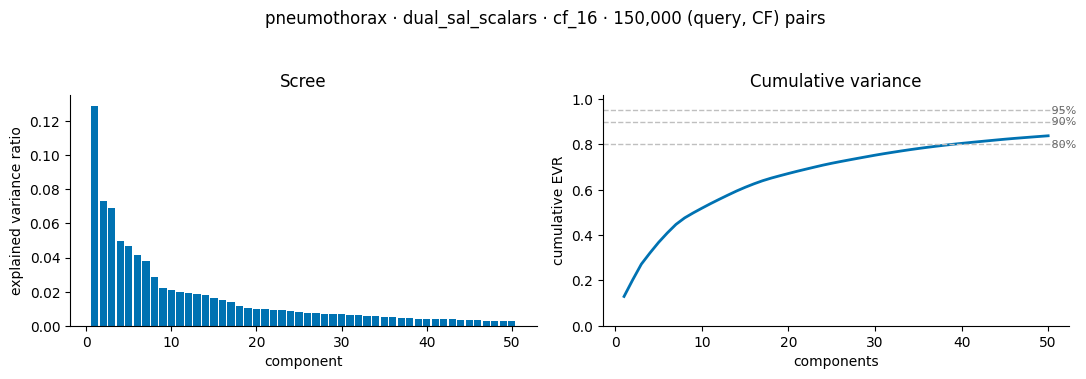

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

axes[0].bar(np.arange(1, len(evr) + 1), evr, color='#0072B2', width=0.85)
axes[0].set(xlabel='component', ylabel='explained variance ratio', title='Scree')

axes[1].plot(np.arange(1, len(cum) + 1), cum, color='#0072B2', lw=2)
for k, c in zip((0.80, 0.90, 0.95), ('#BFBFBF', '#BFBFBF', '#BFBFBF')):
    axes[1].axhline(k, ls='--', lw=1.0, color=c)
    axes[1].text(len(cum), k, f' {k:.0%}', va='center', fontsize=8, color='#666')
axes[1].set(xlabel='components', ylabel='cumulative EVR', title='Cumulative variance', ylim=(0, 1.02))

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'{DISEASE} · {CONFIG} · cf_{CF_COUNT} · {X.shape[0]:,} (query, CF) pairs', y=1.04)
fig.tight_layout()

### Projections

PC1/PC2 coloured by the things that could plausibly drive the leading directions: the true
label, the outer fold (should show *no* structure if the encoders are fold-stable), the C0
query probability, and Δprob = query_prob − cf_prob.

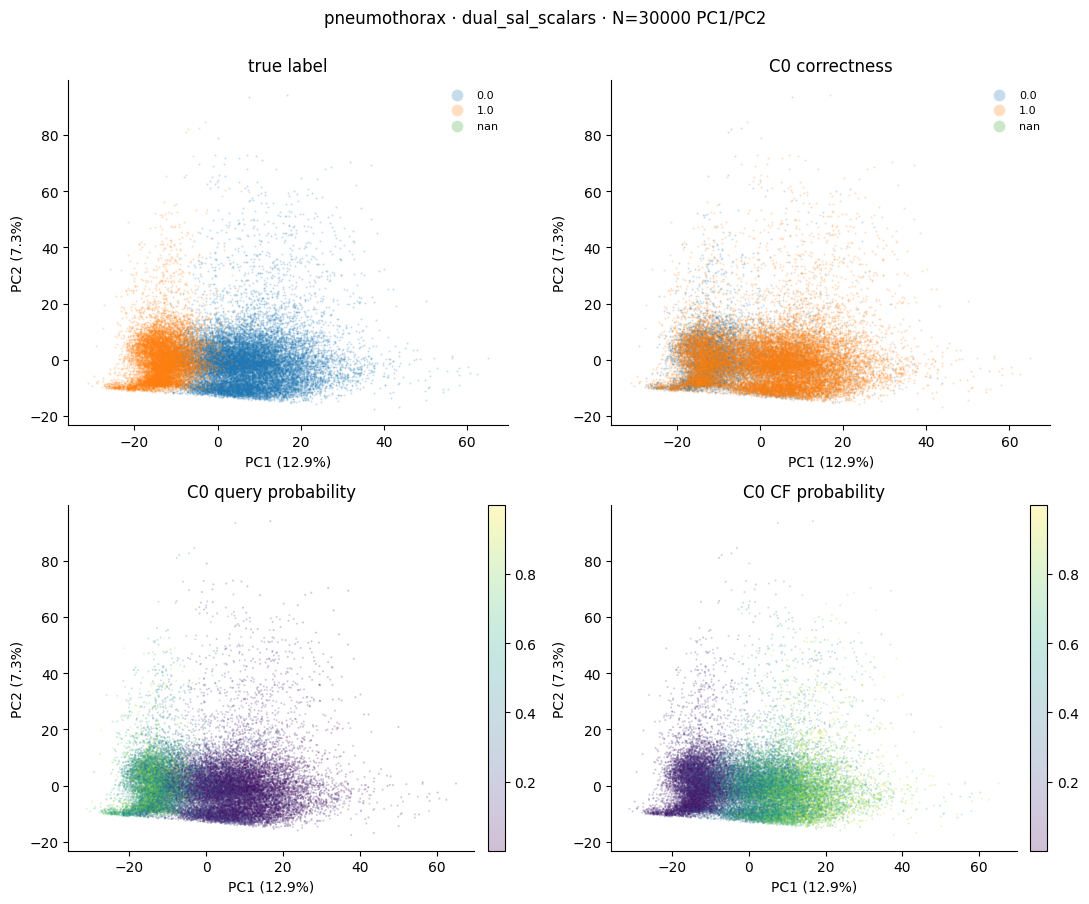

In [ ]:
def scatter_pcs(Z, color, ax, title, cmap='viridis', discrete=False, s=2, alpha=0.25):
    if discrete:
        for v in np.unique(color):
            m = color == v
            ax.scatter(Z[m, 0], Z[m, 1], s=s, alpha=alpha, label=str(v), linewidths=0)
        ax.legend(markerscale=6, fontsize=8, frameon=False, loc='best')
    else:
        sc = ax.scatter(Z[:, 0], Z[:, 1], c=color, s=s, alpha=alpha, cmap=cmap, linewidths=0)
        plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
    ax.set(xlabel=f'PC1 ({evr[0]:.1%})', ylabel=f'PC2 ({evr[1]:.1%})', title=title)
    ax.spines[['top', 'right']].set_visible(False)


# Plot a random subset — 100k overlapping points render as mud, not information.
PLOT_N = min(30_000, Z.shape[0])
pi = np.random.default_rng(SEED).choice(Z.shape[0], PLOT_N, replace=False)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
scatter_pcs(Z[pi], meta['c0_pred'].to_numpy()[pi],      axes[0, 0], 'true label', discrete=True)
scatter_pcs(Z[pi], meta['c0_correct'].to_numpy()[pi],       axes[0, 1], 'C0 correctness', discrete=True)
scatter_pcs(Z[pi], meta['query_prob'].to_numpy()[pi], axes[1, 0], 'C0 query probability')
scatter_pcs(Z[pi], meta['cf_prob'].to_numpy()[pi], axes[1, 1], 'C0 CF probability')

fig.suptitle(f'{DISEASE} · {CONFIG} · N={PLOT_N} PC1/PC2', y=1.00)
fig.tight_layout()

### What do the leading PCs correlate with?

A quick |Spearman| between each of the first components and the scalars. If PC1 is essentially
the C0 probability, the embedding is mostly re-encoding what the tabular pipeline already has.

In [ ]:
from scipy.stats import spearmanr

targets = ['c0_pred', 'query_prob', 'cf_prob', 'delta_prob', 'c0_correct']
rows = []
for pc in range(10):
    row = {'PC': f'PC{pc + 1}', 'EVR': evr[pc]}
    for t in targets:
        v = meta[t].to_numpy(dtype=float)
        ok = ~np.isnan(v)
        row[t] = spearmanr(Z[ok, pc], v[ok]).statistic
    rows.append(row)

corr = pd.DataFrame(rows).set_index('PC')
corr.style.format({'EVR': '{:.3f}', **{t: '{:+.3f}' for t in targets}}) \
          .background_gradient(cmap='coolwarm', vmin=-0.6, vmax=0.6, subset=targets)

,EVR,c0_pred,query_prob,cf_prob,delta_prob,c0_correct
PC,,,,,,
PC1,0.129,-0.816,-0.785,+0.830,-0.856,+0.315
PC2,0.073,+0.119,+0.090,-0.122,+0.117,-0.038
PC3,0.069,-0.143,+0.039,+0.230,-0.149,+0.012
PC4,0.050,+0.079,+0.031,-0.075,+0.054,-0.040
PC5,0.047,+0.138,+0.093,-0.101,+0.091,-0.068
PC6,0.041,-0.046,-0.007,+0.095,-0.083,-0.023
PC7,0.038,+0.093,+0.151,-0.048,+0.084,-0.057
PC8,0.029,+0.326,+0.401,-0.132,+0.188,-0.186
PC9,0.022,+0.139,+0.054,-0.162,+0.145,-0.003


## 4. Per-encoder PCA

The 4096-d vector is four independent 1024-d encoders glued together. A joint PCA can be
dominated by whichever block has the largest raw variance, so fit each block separately and
compare their intrinsic dimensionality — a block that needs far fewer components to reach 90%
is carrying less independent signal.

In [ ]:
block_pcas, block_Z = {}, {}
summary = []

for name, sl in BLOCKS.items():
    p = PCA(n_components=N_COMPONENTS, svd_solver='randomized', random_state=SEED)
    block_Z[name]    = p.fit_transform(X[:, sl])
    block_pcas[name] = p
    c = np.cumsum(p.explained_variance_ratio_)
    summary.append({
        'block':      name,
        'PC1':        p.explained_variance_ratio_[0],
        'PC1-10':     c[9],
        f'PC1-{N_COMPONENTS}': c[-1],
        'n@90%':      int(np.searchsorted(c, 0.90)) + 1 if c[-1] >= 0.90 else np.nan,
        'total var':  p.explained_variance_.sum() / max(1e-12, p.explained_variance_ratio_.sum()),
    })

pd.DataFrame(summary).set_index('block').style.format(
    {'PC1': '{:.3f}', 'PC1-10': '{:.3f}', f'PC1-{N_COMPONENTS}': '{:.3f}',
     'n@90%': '{:.0f}', 'total var': '{:.1f}'})

,PC1,PC1-10,PC1-50,n@90%,total var
block,,,,,
query,0.270,0.753,0.925,35,368.0
cf,0.455,0.811,0.935,27,200.6
q_cam,0.186,0.761,0.973,20,338.8
cf_cam,0.344,0.796,0.963,23,356.5


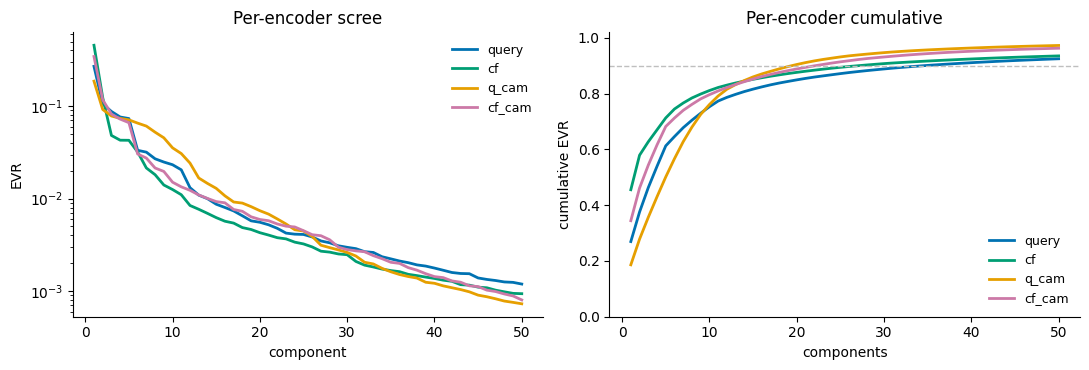

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
colors = {'query': '#0072B2', 'cf': '#009E73', 'q_cam': '#E69F00', 'cf_cam': '#CC79A7'}

for name, p in block_pcas.items():
    c = np.cumsum(p.explained_variance_ratio_)
    axes[0].plot(np.arange(1, len(c) + 1), p.explained_variance_ratio_, color=colors[name], lw=2, label=name)
    axes[1].plot(np.arange(1, len(c) + 1), c, color=colors[name], lw=2, label=name)

axes[0].set(xlabel='component', ylabel='EVR', title='Per-encoder scree', yscale='log')
axes[1].axhline(0.90, ls='--', lw=1.0, color='#BFBFBF')
axes[1].set(xlabel='components', ylabel='cumulative EVR', title='Per-encoder cumulative', ylim=(0, 1.02))
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()

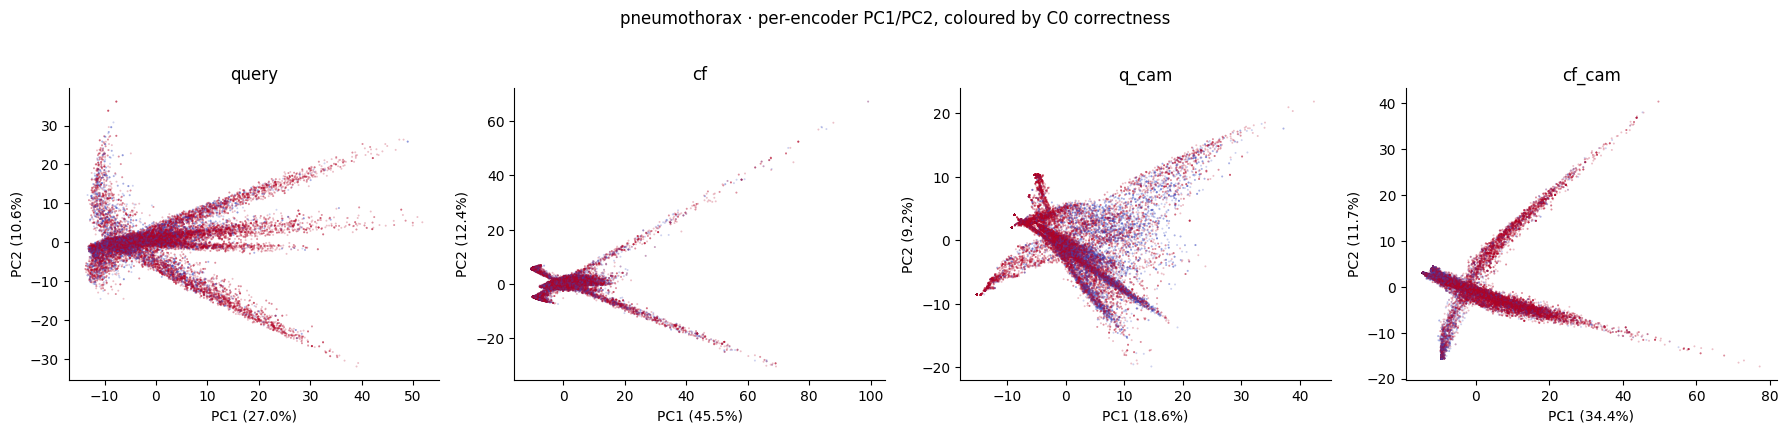

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (name, Zb) in zip(axes, block_Z.items()):
    e = block_pcas[name].explained_variance_ratio_
    sc = ax.scatter(Zb[pi, 0], Zb[pi, 1], c=meta['c0_correct'].to_numpy()[pi],
                    s=2, alpha=0.25, cmap='coolwarm', linewidths=0)
    ax.set(xlabel=f'PC1 ({e[0]:.1%})', ylabel=f'PC2 ({e[1]:.1%})', title=name)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'{DISEASE} · per-encoder PC1/PC2, coloured by C0 correctness', y=1.02)
fig.tight_layout()

## 5. PCA on the query − CF difference

The whole premise of the counterfactual pipeline is that the *difference* between query and CF
carries the signal. Here that difference is available directly in embedding space: the query and
CF encoders are separate towers, but they share the DenseNet architecture, so `query - cf` is a
meaningful contrast (note: **not** weight-shared, so read this as a learned contrast rather than
a metric distance).

In [ ]:
D_img = X[:, BLOCKS['query']] - X[:, BLOCKS['cf']]
D_cam = X[:, BLOCKS['q_cam']] - X[:, BLOCKS['cf_cam']]

diff_pcas, diff_Z = {}, {}
for name, D in [('image Δ (query − cf)', D_img), ('cam Δ (q_cam − cf_cam)', D_cam)]:
    p = PCA(n_components=N_COMPONENTS, svd_solver='randomized', random_state=SEED)
    diff_Z[name]    = p.fit_transform(D)
    diff_pcas[name] = p
    c = np.cumsum(p.explained_variance_ratio_)
    print(f"{name:>24}: PC1 {p.explained_variance_ratio_[0]:.3f} | PC1-10 {c[9]:.3f} | PC1-{N_COMPONENTS} {c[-1]:.3f}")

del D_img, D_cam

    image Δ (query − cf): PC1 0.273 | PC1-10 0.678 | PC1-50 0.896
  cam Δ (q_cam − cf_cam): PC1 0.296 | PC1-10 0.696 | PC1-50 0.939


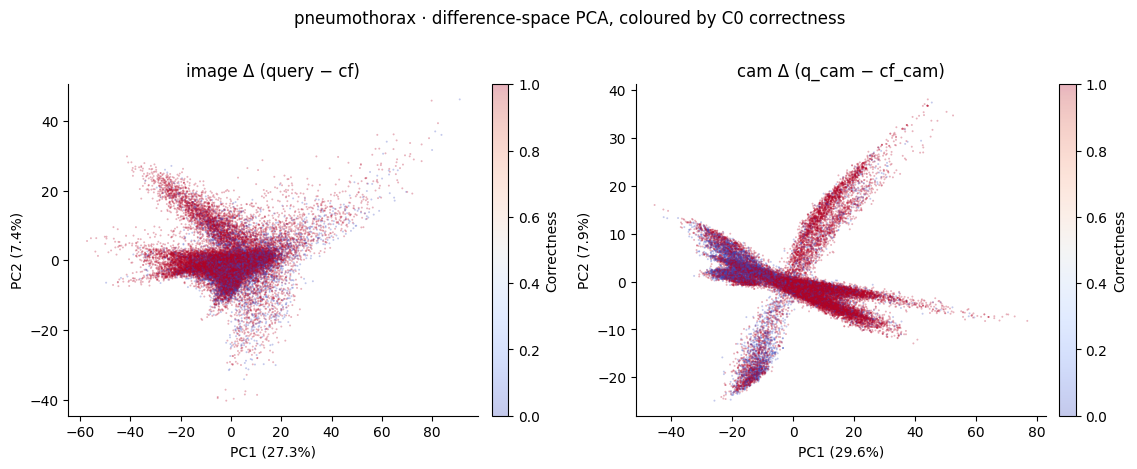

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, (name, Zd) in zip(axes, diff_Z.items()):
    e  = diff_pcas[name].explained_variance_ratio_
    sc = ax.scatter(Zd[pi, 0], Zd[pi, 1], c=meta['c0_correct'].to_numpy()[pi],
                    s=2, alpha=0.3, cmap='coolwarm', linewidths=0)
    plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.03, label='Correctness')
    ax.set(xlabel=f'PC1 ({e[0]:.1%})', ylabel=f'PC2 ({e[1]:.1%})', title=name)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'{DISEASE} · difference-space PCA, coloured by C0 correctness', y=1.01)
fig.tight_layout()

## 6. Sample-level PCA (mean over the K counterfactuals)

Everything above is at (query, CF) granularity, so each query image contributes K correlated
rows and the PCs partly describe within-sample CF variation. Pooling to one row per query gives
the sample-level view that a downstream classifier would actually consume, and lets us split
within-sample from between-sample variance.

In [ ]:
codes, uniq = pd.factorize(meta['sample_path'], sort=False)
n_samples   = len(uniq)

sums   = np.zeros((n_samples, X.shape[1]), dtype=np.float64)
counts = np.bincount(codes, minlength=n_samples).astype(np.float64)
np.add.at(sums, codes, X)               # chunk this if X gets much larger
X_samp = (sums / counts[:, None]).astype(np.float32)
del sums

samp_meta = (meta.assign(_code=codes)
                 .groupby('_code')
                 .agg(sample_path=('sample_path', 'first'),
                      fold=('fold', 'first'),
                      label=('label', 'first'),
                      query_prob=('query_prob', 'first'),
                      c0_pred=('c0_pred', 'first'),
                      c0_correct=('c0_correct', 'first'),
                      mean_cf_prob=('cf_prob', 'mean'),
                      mean_delta=('delta_prob', 'mean'),
                      k=('cf_path', 'size'))
                 .sort_index())

print(f"{n_samples:,} samples, K per sample: min {counts.min():.0f} / median {np.median(counts):.0f} / max {counts.max():.0f}")

pca_s = PCA(n_components=min(N_COMPONENTS, n_samples - 1), svd_solver='randomized', random_state=SEED)
Z_s   = pca_s.fit_transform(X_samp)
c_s   = np.cumsum(pca_s.explained_variance_ratio_)
print(f"sample-level: PC1 {pca_s.explained_variance_ratio_[0]:.3f} | PC1-10 {c_s[9]:.3f} | PC1-{len(c_s)} {c_s[-1]:.3f}")

27,685 samples, K per sample: min 1 / median 5 / max 14
sample-level: PC1 0.145 | PC1-10 0.556 | PC1-50 0.877


In [ ]:
# Variance decomposition: how much of the pair-level variance is *within* a query's K CFs?
total_var   = X.var(axis=0, ddof=0).sum()
between_var = np.average((X_samp - X.mean(axis=0)) ** 2, axis=0, weights=counts).sum()
within_frac = 1 - between_var / total_var
print(f"between-sample: {between_var / total_var:.1%}")
print(f"within-sample (across the K CFs): {within_frac:.1%}")

between-sample: 77.5%
within-sample (across the K CFs): 22.5%


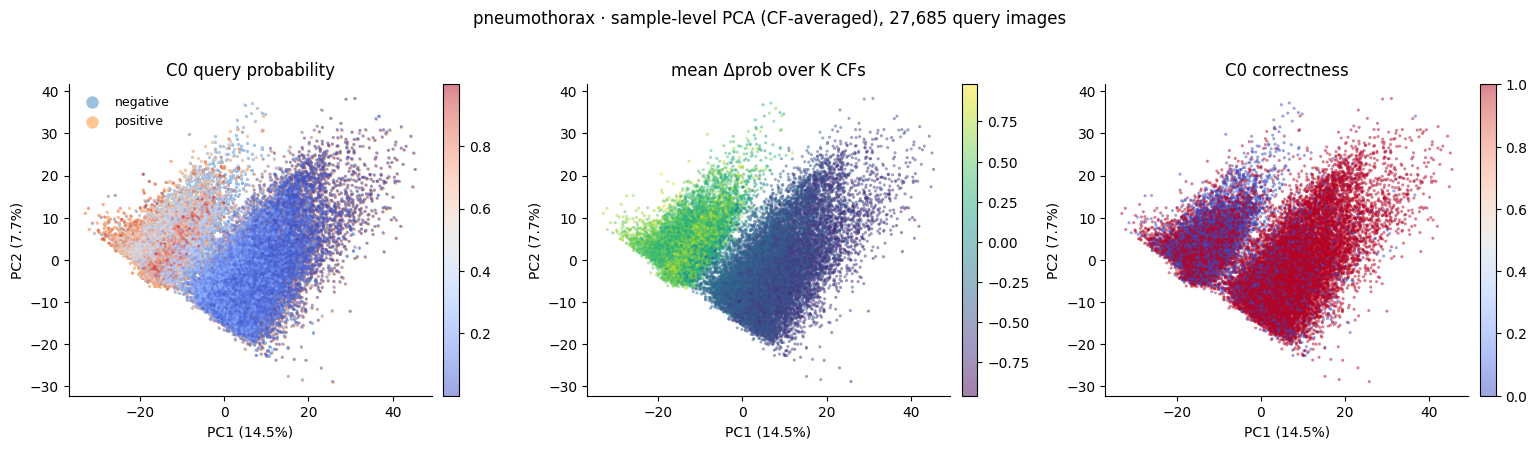

In [ ]:
es = pca_s.explained_variance_ratio_
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

for v, lab in [(0, 'negative'), (1, 'positive')]:
    m = samp_meta['label'].to_numpy() == v
    axes[0].scatter(Z_s[m, 0], Z_s[m, 1], s=5, alpha=0.45, label=lab, linewidths=0)
axes[0].legend(markerscale=4, fontsize=9, frameon=False)
axes[0].set_title('true label')

for c, arr, title in [(0, samp_meta['query_prob'], 'C0 query probability'),
                      (1, samp_meta['mean_delta'], 'mean Δprob over K CFs'),
                      (2, samp_meta['c0_correct'], 'C0 correctness')]:
    sc = axes[c].scatter(Z_s[:, 0], Z_s[:, 1], c=arr, s=5, alpha=0.5,
                         cmap='viridis' if c == 1 else 'coolwarm', linewidths=0)
    plt.colorbar(sc, ax=axes[c], fraction=0.046, pad=0.03)
    axes[c].set_title(title)

for ax in axes:
    ax.set(xlabel=f'PC1 ({es[0]:.1%})', ylabel=f'PC2 ({es[1]:.1%})')
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'{DISEASE} · sample-level PCA (CF-averaged), {n_samples:,} query images', y=1.01)
fig.tight_layout()

## 7. Optional — full data via IncrementalPCA

Set `MAX_ROWS = None` above and you have ~700k x 4096 float32 (~11 GB), which is more than most
nodes want to hold. `IncrementalPCA` streams the folds instead, one `partial_fit` per chunk, and
never materialises the full matrix. Slower and slightly less accurate on the tail components,
but the leading PCs match the in-memory fit closely.

Left unrun by default — flip `RUN_IPCA` to `True`.

In [ ]:
RUN_IPCA   = True
CHUNK_ROWS = 20_000

if RUN_IPCA:
    ipca = IncrementalPCA(n_components=N_COMPONENTS)
    for f in range(N_FOLDS):
        with np.load(os.path.join(EMB_DIR, f'fold_{f}_pair_embeddings.npz'), allow_pickle=True) as d:
            emb = d['emb']
            for start in range(0, emb.shape[0], CHUNK_ROWS):
                chunk = emb[start:start + CHUNK_ROWS].astype(np.float32)
                if chunk.shape[0] < N_COMPONENTS:
                    continue          # partial_fit needs n_samples >= n_components
                ipca.partial_fit(chunk)
        print(f"fold {f} done")

    ci = np.cumsum(ipca.explained_variance_ratio_)
    print(f"\nIPCA: PC1 {ipca.explained_variance_ratio_[0]:.3f} | PC1-10 {ci[9]:.3f} | PC1-{N_COMPONENTS} {ci[-1]:.3f}")
else:
    print('skipped (RUN_IPCA = False)')

fold 0 done
fold 1 done


## 8. Persist the reduced representations

Saves the pair-level and sample-level scores plus the fitted `PCA` objects, so downstream work
(fusion with the tabular features, a PCA-reduced MLP baseline) can start from here instead of
re-reading 5.5 GB of npz.

In [ ]:
import joblib

OUT_DIR = os.path.join(EMB_DIR, 'pca')
os.makedirs(OUT_DIR, exist_ok=True)
tag = 'all' if MAX_ROWS is None else f'sub{MAX_ROWS}'

np.savez_compressed(
    os.path.join(OUT_DIR, f'pair_pca_{tag}.npz'),
    Z=Z.astype(np.float32),
    explained_variance_ratio=pca.explained_variance_ratio_,
    sample_paths=meta['sample_path'].to_numpy(),
    cf_paths=meta['cf_path'].to_numpy(),
    labels=meta['label'].to_numpy(),
    folds=meta['fold'].to_numpy(),
)
np.savez_compressed(
    os.path.join(OUT_DIR, f'sample_pca_{tag}.npz'),
    Z=Z_s.astype(np.float32),
    explained_variance_ratio=pca_s.explained_variance_ratio_,
    sample_paths=samp_meta['sample_path'].to_numpy(),
    labels=samp_meta['label'].to_numpy(),
    folds=samp_meta['fold'].to_numpy(),
)
joblib.dump({'full': pca, 'sample': pca_s, 'blocks': block_pcas, 'diffs': diff_pcas},
            os.path.join(OUT_DIR, f'pca_models_{tag}.joblib'))

print(f"wrote -> {OUT_DIR}")
for f in sorted(os.listdir(OUT_DIR)):
    print(' ', f, f"{os.path.getsize(os.path.join(OUT_DIR, f)) / 1e6:.1f} MB")

wrote -> /work3/s251710/thesis_results/C2_cnn/effusion/late/dual_sal_scalars/cf_16/pca
  pair_pca_sub20000.npz 19.8 MB
  pca_models_sub20000.joblib 2.9 MB
  sample_pca_sub20000.npz 7.9 MB
